<a href="https://colab.research.google.com/github/yadavanshudstcims2025-cell/machine-learning-short-codes/blob/main/california_housing_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
df.shape
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
The dataset contains 20,640 rows and 8 features.
The target variable is `MedHouseVal`, which represents median house value.

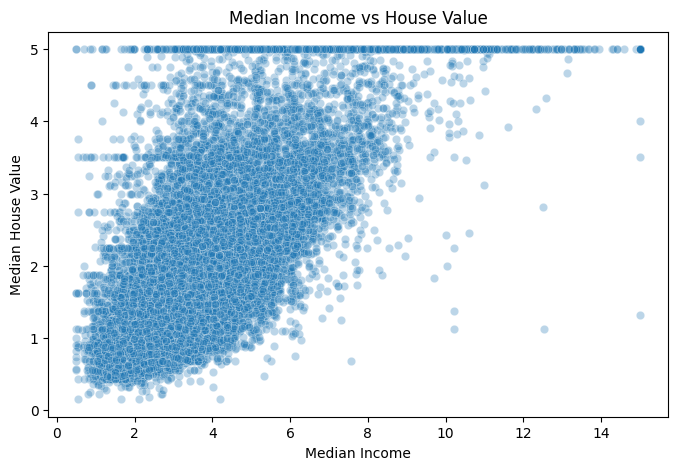

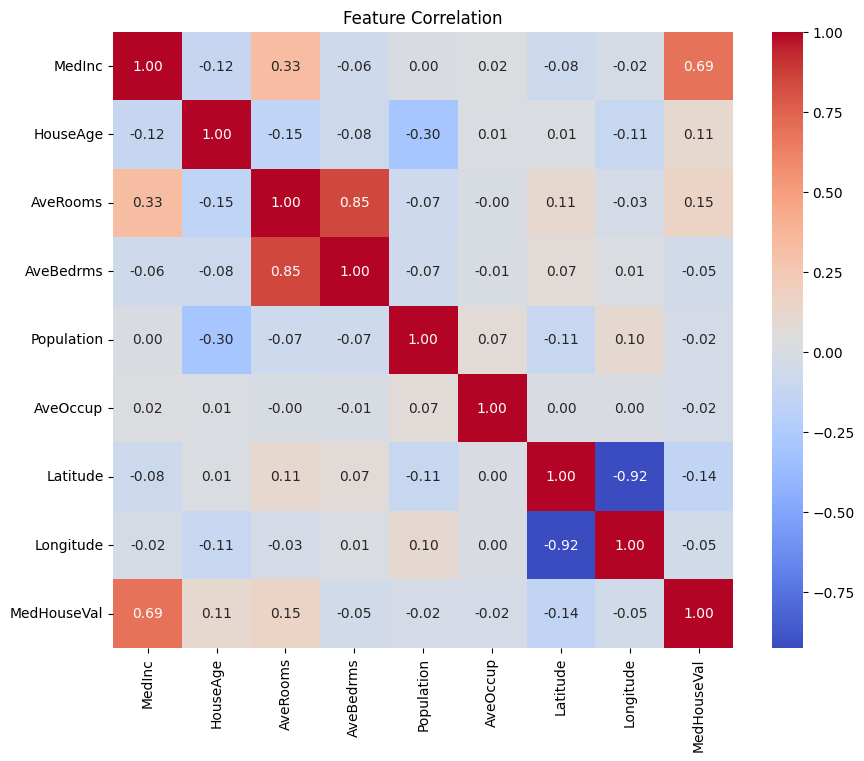

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["MedInc"], y=df["MedHouseVal"], alpha=0.3)
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs House Value")
plt.show()
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation")
plt.show()

In [ ]:
Median income usually has the strongest positive relationship with house value

In [ ]:

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 8)
Testing data: (4128, 8)


In [ ]:

model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:

coefficients = pd.DataFrame(
    {
        "Feature": X.columns,
        "Coefficient": model.coef_
    }
).sort_values(by="Coefficient", ascending=False)

coefficients

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


In [ ]:
Interpretation: A positive coefficient means that increasing that feature is associated with a higher predicted house value, while holding other features constant.

In [ ]:
print("Intercept:", model.intercept_)

Intercept: -37.02327770606405


In [ ]:
y_pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MAE: 0.533
MSE: 0.556
RMSE: 0.746
R2 Score: 0.576


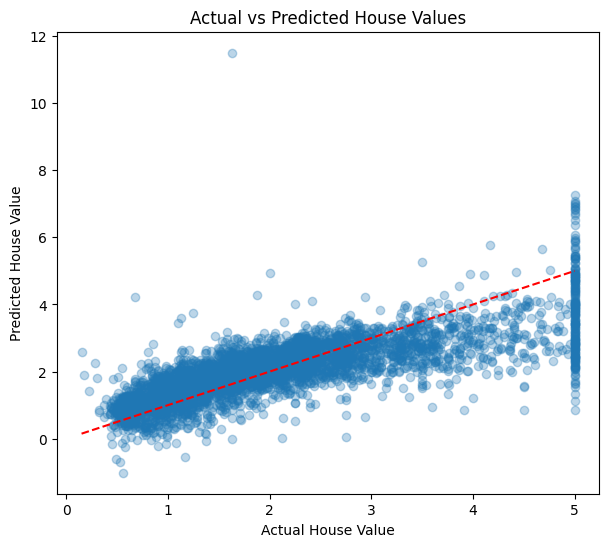

In [ ]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predicted House Values")
plt.show()

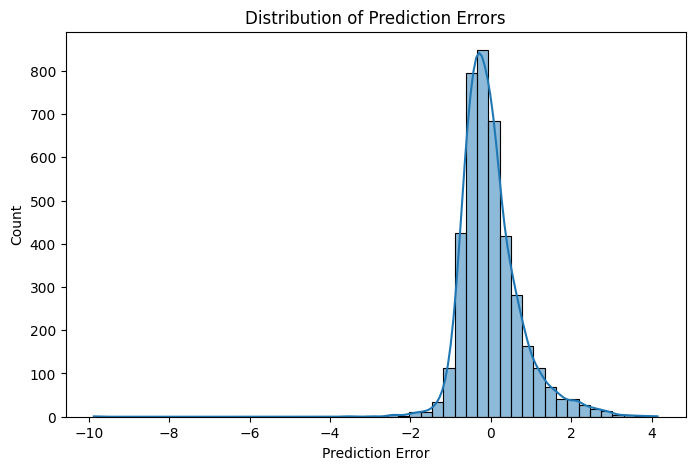

In [ ]:
errors = y_test - y_pred

plt.figure(figsize=(8, 5))
sns.histplot(errors, bins=50, kde=True)
plt.xlabel("Prediction Error")
plt.title("Distribution of Prediction Errors")
plt.show()

In [ ]:
## Results

The Linear Regression model was trained on the California Housing dataset.

The model’s performance was evaluated using MAE, RMSE, and R² score.

Median income appeared to be one of the most important features for predicting house value.

## What I Learned

- Linear regression assumes an approximately linear relationship between features and target.
- Train-test splitting is necessary to check performance on unseen data.
- RMSE and MAE help measure prediction error.
- R² explains how much variation in the target is captured by the model.
- Visualization helps identify whether predictions are systematically biased.